# Nested-Archive Experiment: Does a Longer Training Archive Help Analog-Ensemble Wind-Gust Forecasting?

**Phase B — controlled archive-size revision for Weather and Forecasting (AMS)**
Repository: [Mahinul372/ML-Analog-Ensemble-Severe-Weather](https://github.com/Mahinul372/ML-Analog-Ensemble-Severe-Weather)

The earlier 1-year vs 8-years-10-months comparison changed the test
period along with the training archive, so archive size and test-period
difficulty were confounded. This revision fixes that: **one fixed test
period (2025-11-01 → 2026-11-01) and one fixed validation period
(2025-10-01 → 2025-10-31) for every archive** — only the training
length varies (1 / 3 / 5 / 8 years, identical cutoff 2025-09-30).
Five methods run on all four archives under the identical protocol
(K = 15, ±168 h exclusion, analogs from the training pool only):

| Method | Search space | K |
|---|---|---|
| **Raw NWP** | — (deterministic `fcst_gust`) | — |
| **MOS** | OLS regression on the 4 standardized forecast predictors | — |
| **Traditional AnEn** | 4-D standardized forecast space, Euclidean | 15 |
| **Deep-AnEn-Regression** | 16-D regression-trained latent embedding, Euclidean | 15 |
| **Deep Analog (Hu et al., 2023)** | 20-D LSTM triplet embedding, Euclidean | 15 |

**Terminology.** "High-gust events" are individual test-window hours
with observed gust ≥ 35 km/h (1,286 of them). "Storm" is used ONLY for
independent episodes obtained by declustering those events (a gap of
≥ 24 h between events starts a new episode; 81 episodes in the test
period).

**Data.** Forecasts: Open-Meteo Previous-Runs API (no `models`
parameter, so the provider default — auto / best-match — applies;
empirically the returned series is identical to NOAA GFS (seamless)
at sampled windows in 2018, 2021, 2023 and 2025). Plain variables are
the Day-0 offset — the forecast from the most recent model run before
the valid hour; GFS updates every 6 h, so the effective lead time is
0–6 h. Valid time is the hourly UTC timestamp itself. The endpoint
exposes no per-hour model attribution or run-initialisation field.
Reference observations: ERA5 reanalysis via the Open-Meteo Archive
API — reanalysis-based reference data, not independent station
observations (see the limitations note in §8).

**Interpolation (reviewer revision 4).** The original `fetch_data.py`
interpolated short gaps before dropping NaNs. A re-fetch of the full
2018-01-01 → 2026-11-01 window with a fresh cache and NO interpolation
returned 77,448 rows with **0 NaN cells in every column**, identical to
the files in use (max absolute difference 0.0 in all 8 columns) — so
the interpolation was a no-op: no value in the archive is interpolated,
in particular no `obs_gust` value. The interpolation code has been
removed from `fetch_data.py` (missing rows are now dropped instead);
all results stand unchanged.

**The 8-year archive.** The reviewer's 8-year training start is
2017-11-01; the 8-year archive uses the forecast data available from
the source, beginning 1 January 2018, so its effective training period
is 2018-01-01 → 2025-09-30 (7 years 9 months).

**How to run:** open in Google Colab → *Runtime → Run all* (CPU is
fine — this notebook loads saved results and does not retrain).

In [1]:
# --- Setup ----------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore")

import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "properscoring"])

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import properscoring
from IPython.display import display, Image

np.random.seed(42)

# Locate the repo root.
if os.path.exists("data/atlanta_weather_archive_1yr.csv"):
    pass
elif os.path.exists("../data/atlanta_weather_archive_1yr.csv"):
    os.chdir("..")
else:
    print("Cloning repository ...")
    os.system("git clone -q https://github.com/Mahinul372/ML-Analog-Ensemble-Severe-Weather.git")
    os.chdir("ML-Analog-Ensemble-Severe-Weather")
print("Working directory:", os.getcwd())

sys.path.insert(0, os.getcwd())
from data_prep import (
    NESTED_REGIMES,
    NESTED_EXPECTED_ROWS,
    STORM_THRESHOLD,
    assign_episode_ids,
    get_episodes,
    get_storm_events,
    load_and_split,
)

ARCH_LABELS = {"nested_1yr": "1-year", "nested_3yr": "3-year",
               "nested_5yr": "5-year", "nested_8yr": "8-year"}
METHODS = ["Raw NWP", "MOS", "Traditional AnEn",
           "Deep-AnEn-Regression", "Deep Analog (Hu et al., 2023)"]

Working directory: /home/hatch/workspace/ml-analog-ensemble-severe-weather


## §1 — Design verification: splits, events, episodes

The nested design is verified, not assumed: every archive must have
the exact expected split sizes, the identical fixed test window, and
the identical 1,286 high-gust events / 81 episodes.

In [2]:
# --- Verify the nested splits ---------------------------------------------
rows = []
for regime in NESTED_REGIMES:
    df, train_df, val_df, test_df, reg = load_and_split(regime=regime)
    assert reg == regime
    assert (len(train_df), len(val_df), len(test_df)) == NESTED_EXPECTED_ROWS[regime], regime
    events = get_storm_events(test_df, STORM_THRESHOLD)
    episodes = get_episodes(events)
    assert len(events) == 1286 and len(episodes) == 81, regime
    rows.append({
        "archive": ARCH_LABELS[regime],
        "train_start": str(train_df["timestamp"].min()),
        "train_end": str(train_df["timestamp"].max()),
        "n_train": len(train_df),
        "n_val": len(val_df),
        "n_test": len(test_df),
        "n_high_gust_events": len(events),
        "n_episodes": len(episodes),
        "peak_gust_kmh": float(events["obs_gust"].max()),
    })
design = pd.DataFrame(rows)
display(design)
print("Test window (all archives): 2025-11-01 00:00 -> 2026-11-01 23:00 UTC")
print("Validation window (all archives): 2025-10-01 -> 2025-10-31 UTC")
print("Peak test event: 2026-01-31 20:00 UTC, 77.0 km/h")

,archive,train_start,train_end,n_train,n_val,n_test,n_high_gust_events,n_episodes,peak_gust_kmh
0,1-year,2024-11-01 00:00:00+00:00,2025-09-30 23:00:00+00:00,8016,744,8784,1286,81,77.03999
1,3-year,2022-11-01 00:00:00+00:00,2025-09-30 23:00:00+00:00,25560,744,8784,1286,81,77.03999
2,5-year,2020-11-01 00:00:00+00:00,2025-09-30 23:00:00+00:00,43080,744,8784,1286,81,77.03999
3,8-year,2018-01-01 00:00:00+00:00,2025-09-30 23:00:00+00:00,67920,744,8784,1286,81,77.03999


Test window (all archives): 2025-11-01 00:00 -> 2026-11-01 23:00 UTC
Validation window (all archives): 2025-10-01 -> 2025-10-31 UTC
Peak test event: 2026-01-31 20:00 UTC, 77.0 km/h


## §2 — Tables 1 and 2: data sources and methods

Table 1 (data sources, variables, coverage, missing-data statistics)
and Table 2 (methods, configurations, hyperparameters) are loaded from
the saved CSVs produced by `nested_tables.py`.

In [3]:
# --- Tables 1 and 2 --------------------------------------------------------
print("Table 1 — Data sources, variables, temporal coverage, missing-data statistics")
display(pd.read_csv("metrics/nested_table1.csv"))
print("\nTable 2 — Forecasting methods, configurations, hyperparameters")
display(pd.read_csv("metrics/nested_table2.csv"))

Table 1 — Data sources, variables, temporal coverage, missing-data statistics


,source,role,variables,units,temporal_coverage,rows,missing_values,notes
0,Open-Meteo Previous-Runs API (previous-runs-ap...,NWP forecast (predictors),"temperature_2m, wind_speed_10m, wind_gusts_10m...","degC, km/h, km/h, hPa",2018-01-01 00:00 -> 2026-11-01 23:00 UTC (hourly),77448,0,No models parameter passed: provider default (...
1,Open-Meteo Archive API (archive-api.open-meteo...,Reference observations (target),"temperature_2m, wind_speed_10m, wind_gusts_10m...","degC, km/h, km/h, hPa",2018-01-01 00:00 -> 2026-11-01 23:00 UTC (hourly),77448,0,"ERA5 reanalysis-based reference data, not inde..."
2,Nested design — fixed test period (all archives),Evaluation,obs_gust >= 35 km/h defines high-gust events,km/h,"2025-11-01 00:00 -> 2026-11-01 23:00 UTC (8,78...",8784,0,"1,286 high-gust events; 81 independent episode..."
3,Nested design — fixed validation period (all a...,Early stopping / model selection only,all,-,2025-10-01 00:00 -> 2025-10-31 23:00 UTC (744 h),744,0,Never used for fitting or for test evaluation.
4,Nested design — training periods (identical cu...,Training pools,all,-,"1-year: 2024-11-01 -> 2025-09-30 (8,016 rows);...",144576,0,Nested pools (each longer archive contains the...



Table 2 — Forecasting methods, configurations, hyperparameters


,method,type,configuration,hyperparameters,similarity_space
0,Raw NWP,Deterministic baseline,"Forecast gust (fcst_gust) used directly, no po...",-,-
1,MOS (Model Output Statistics),Deterministic baseline,Ordinary least-squares linear regression of ob...,"OLS, closed form; intercept + 4 coefficients",-
2,Traditional AnEn,"Analog ensemble (Delle Monache et al. 2011, 2013)",Euclidean nearest neighbours in standardized f...,K=15; exclusion 168 h,4-D (standardized forecasts)
3,Deep-AnEn-Regression,Learned analog ensemble,PyTorch encoder Linear 4->32 -> ReLU -> Dropou...,Adam lr 1e-3; MSE vs standardized obs_gust; 30...,16-D latent
4,"Deep Analog (Hu et al., 2023)",Learned analog ensemble (triplet network),"3-layer LSTM (20 hidden, dropout 0.01) + linea...",Adam lr 0.005; margin 0.9 (official default); ...,20-D embedding


## §3 — Results: Table 3 (verification scores + uncertainty)

Scores are **recomputed here from the saved per-event arrays** (never
copied from a metric file) and cross-checked against the per-method
metric files in §6. CRPS is the empirical ensemble CRPS for the three
ensemble methods and the mean absolute error for the deterministic
methods (Raw NWP, MOS) — the exact single-member equivalent.

In [4]:
# --- Recompute scores from the per-event arrays ---------------------------
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

def mae(a, b):
    return float(np.mean(np.abs(a - b)))

def load_regime(regime):
    mos = np.load(f"metrics/nested_mos_errors_{regime}.npz")
    trad = np.load(f"metrics/nested_traditional_errors_{regime}.npz")
    regr = np.load(f"metrics/nested_regression_errors_{regime}.npz")
    trip = np.load(f"metrics/nested_triplet_errors_{regime}.npz")
    for name, arr in [("trad", trad), ("regr", regr), ("trip", trip)]:
        assert (arr["timestamps"] == mos["timestamps"]).all(), f"{regime}/{name}: timestamps differ"
        assert (arr["obs"] == mos["obs"]).all(), f"{regime}/{name}: obs differ"
    obs = mos["obs"]
    return {
        "Raw NWP": (mos["raw_fcst"], None),
        "MOS": (mos["mos"], None),
        "Traditional AnEn": (trad["members"].mean(axis=1), trad["members"]),
        "Deep-AnEn-Regression": (regr["members"].mean(axis=1), regr["members"]),
        "Deep Analog (Hu et al., 2023)": (trip["members"].mean(axis=1), trip["members"]),
    }, obs

table3_rows = []
for regime in NESTED_REGIMES:
    fcst, obs = load_regime(regime)
    for m in METHODS:
        mean, members = fcst[m]
        crps = mae(mean, obs) if members is None else float(
            np.mean(properscoring.crps_ensemble(obs, members)))
        table3_rows.append({
            "archive": ARCH_LABELS[regime], "method": m,
            "RMSE (km/h)": round(rmse(mean, obs), 2),
            "MAE (km/h)": round(mae(mean, obs), 2),
            "CRPS (km/h)": round(crps, 2),
        })
table3 = pd.DataFrame(table3_rows)
display(table3)
with open("metrics/nested_comparison_metrics.json") as f:
    comp = json.load(f)
print("Saved Table 3 (with bootstrap CIs + DM p-values): metrics/nested_table3.csv")

,archive,method,RMSE (km/h),MAE (km/h),CRPS (km/h)
0,1-year,Raw NWP,12.79,10.87,10.87
1,1-year,MOS,7.38,5.72,5.72
2,1-year,Traditional AnEn,8.13,6.23,4.66
3,1-year,Deep-AnEn-Regression,8.22,6.42,4.76
4,1-year,"Deep Analog (Hu et al., 2023)",10.44,8.03,6.23
5,3-year,Raw NWP,12.79,10.87,10.87
6,3-year,MOS,7.81,6.12,6.12
7,3-year,Traditional AnEn,8.29,6.41,4.81
8,3-year,Deep-AnEn-Regression,8.35,6.51,4.86
9,3-year,"Deep Analog (Hu et al., 2023)",9.56,7.21,5.60


Saved Table 3 (with bootstrap CIs + DM p-values): metrics/nested_table3.csv


## §4 — Figures 1–4

Fig 1 is the experimental framework; Fig 2 is the overall verification
on the 8-year archive (the primary configuration) with block-bootstrap
uncertainty intervals and calibration diagnostics; Fig 3 is the
archive-size sensitivity — the central result; Fig 4 is the
representative high-gust episode, selected by the predefined rule
(highest observed peak gust in the test period).

Fig 1 — Experimental framework


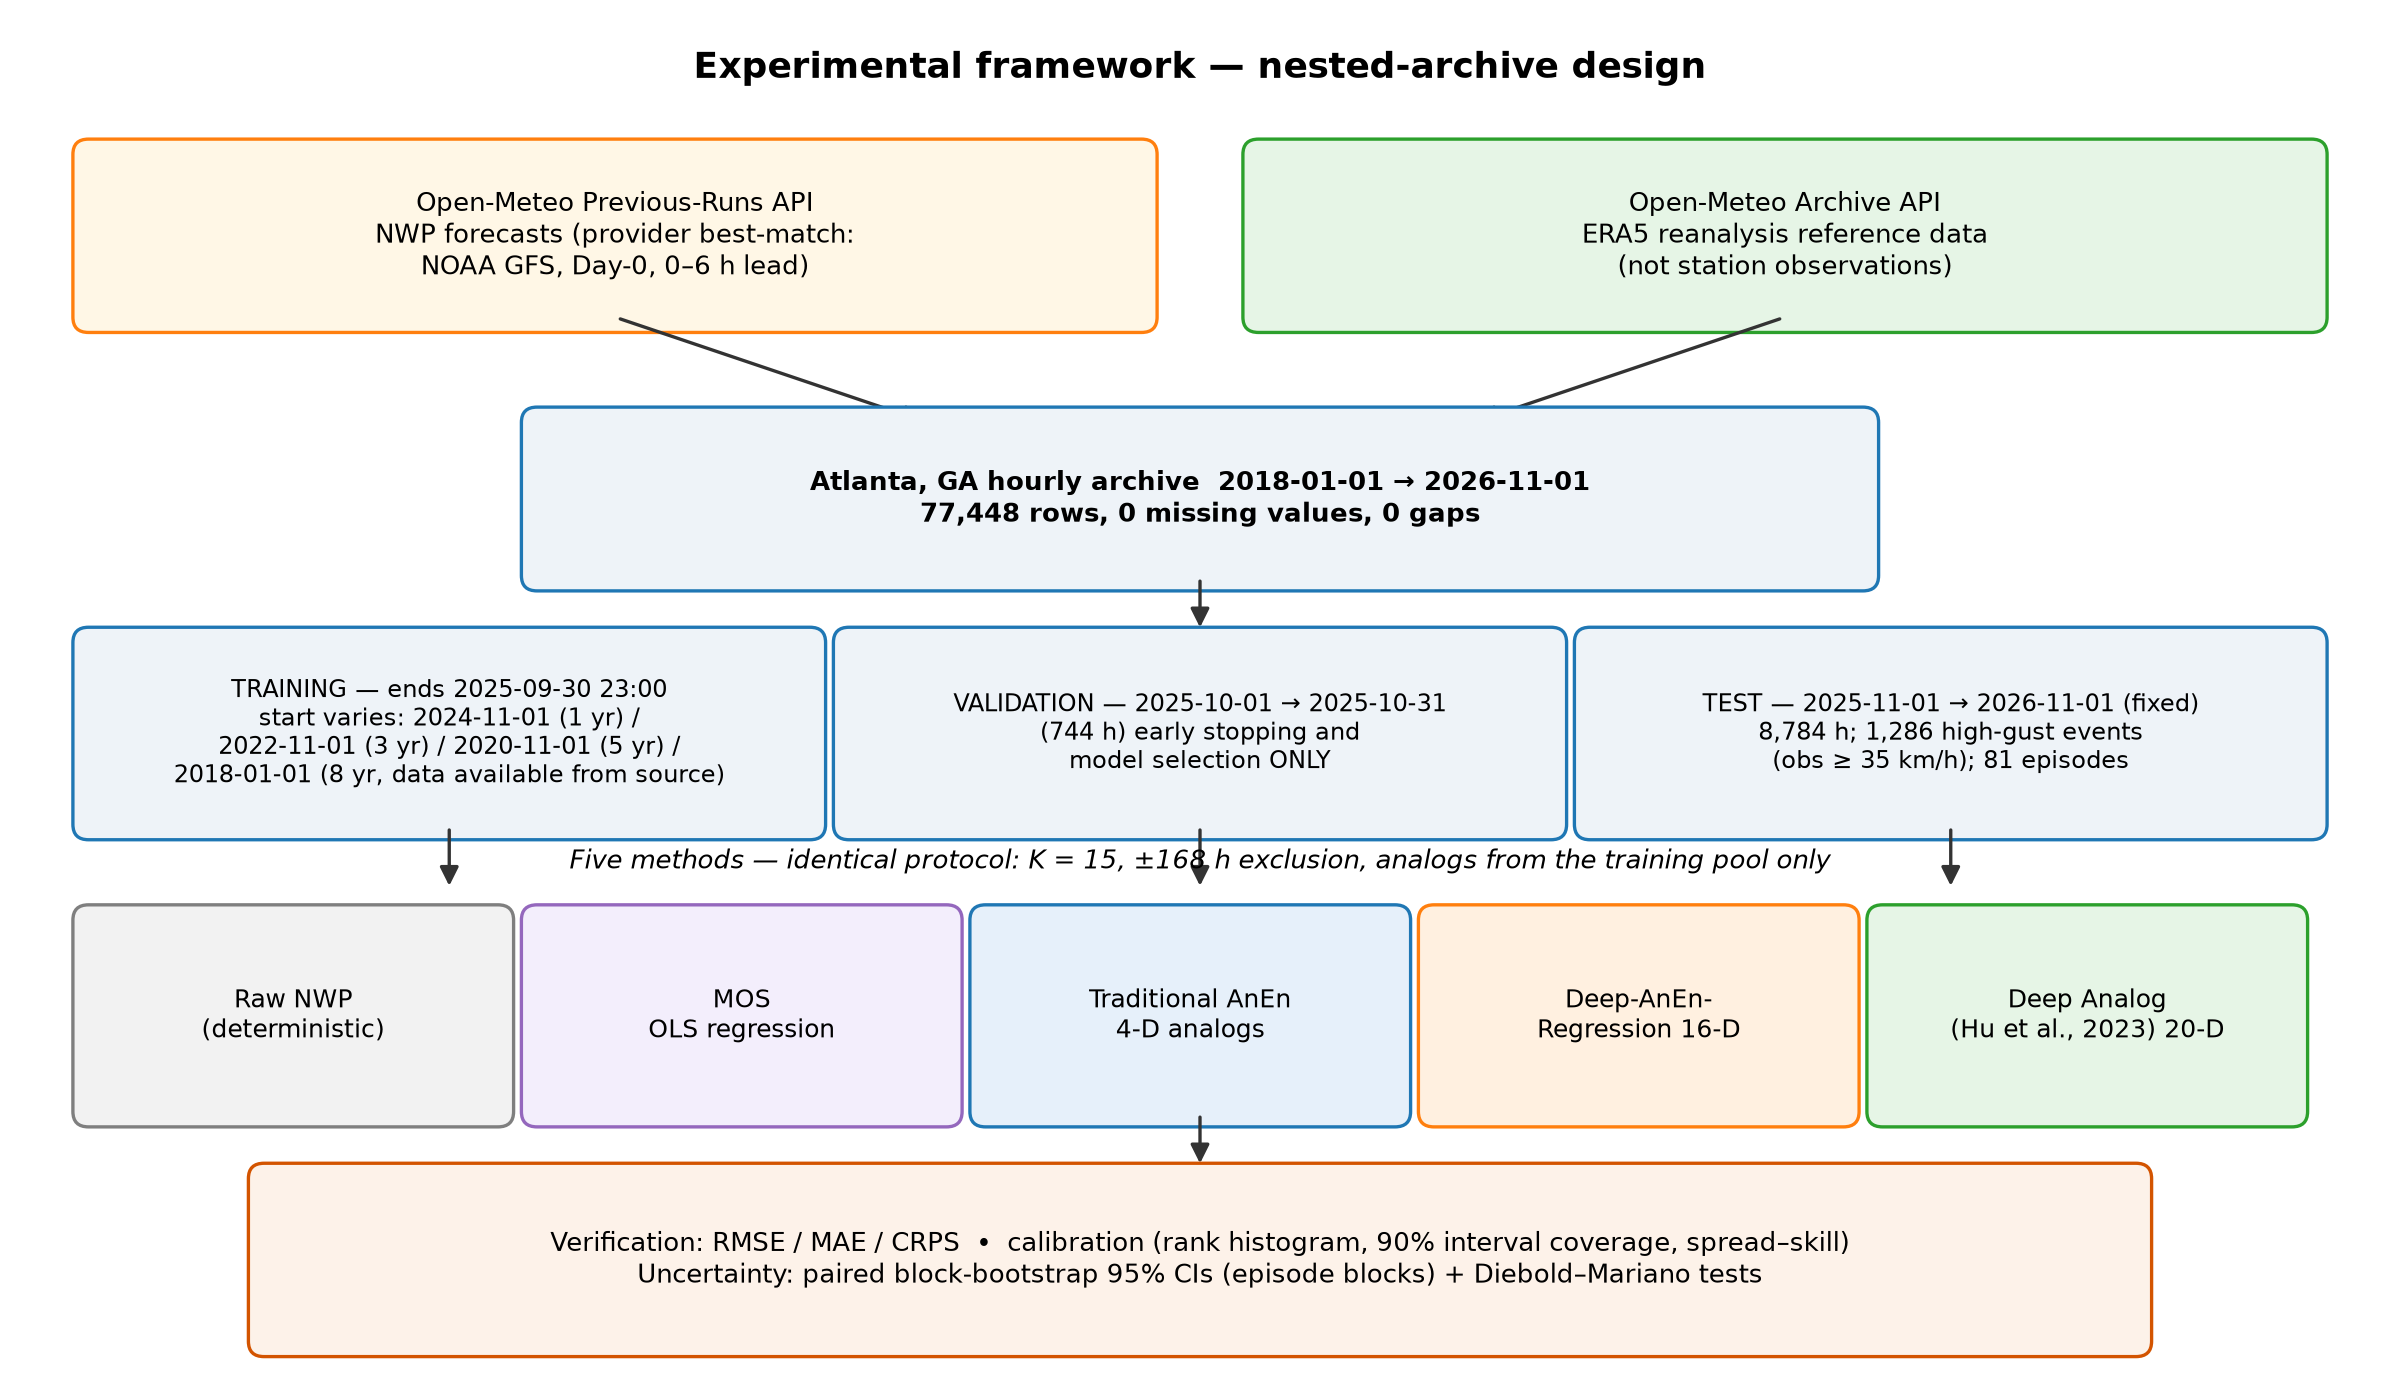

Fig 2 — Overall verification (8-year archive)


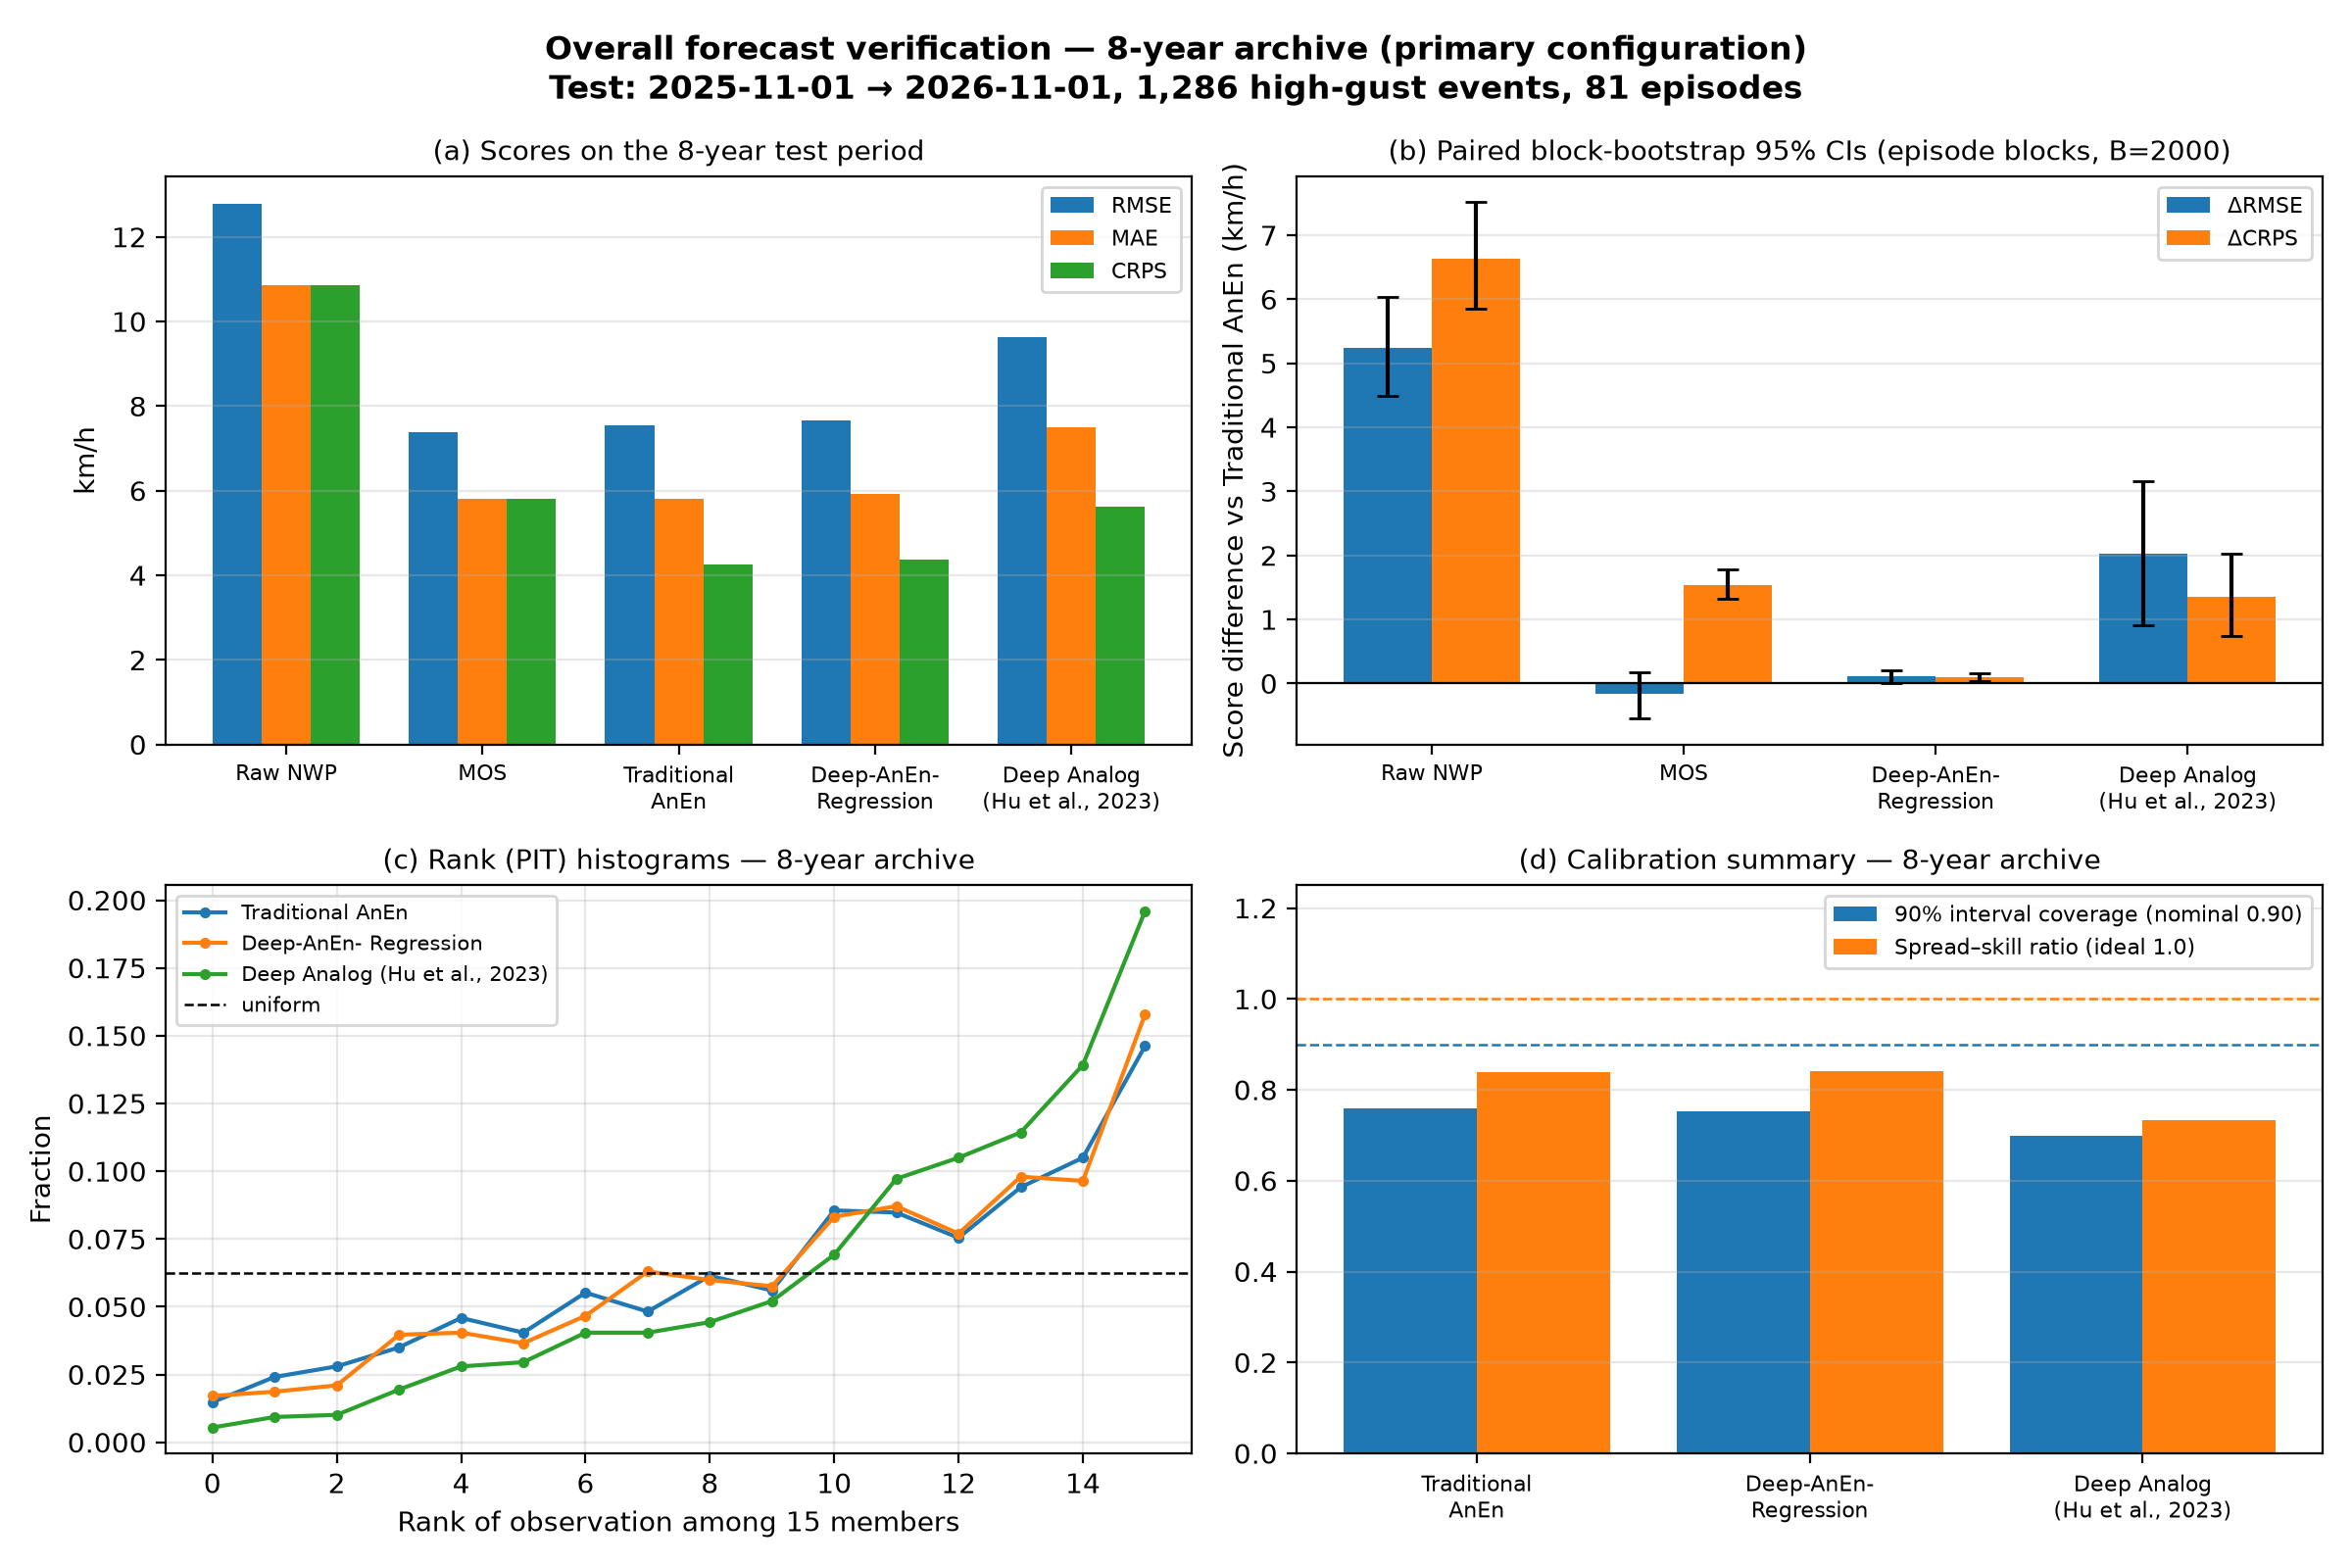

Fig 3 — Archive-size sensitivity


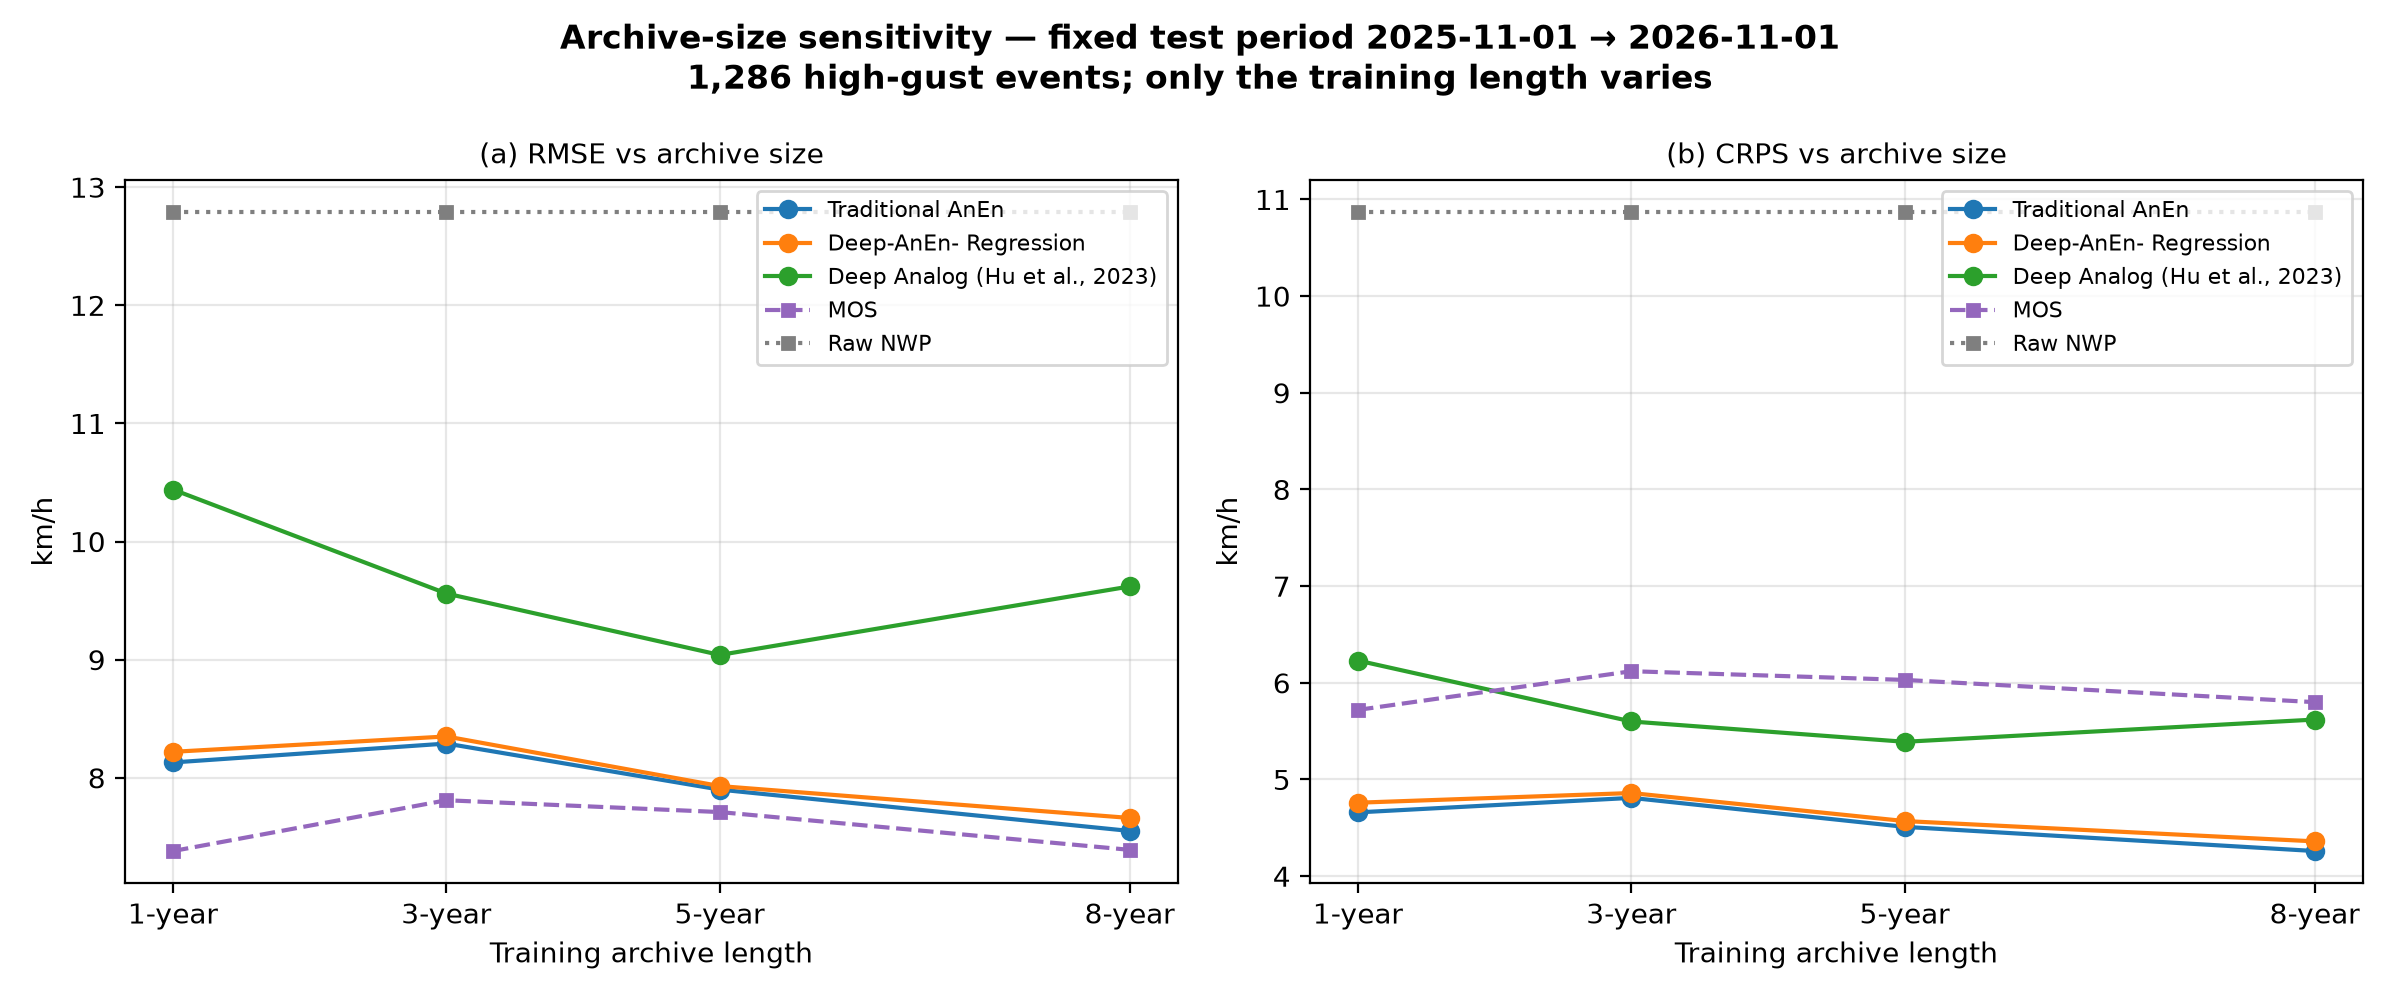

Fig 4 — Representative high-gust episode


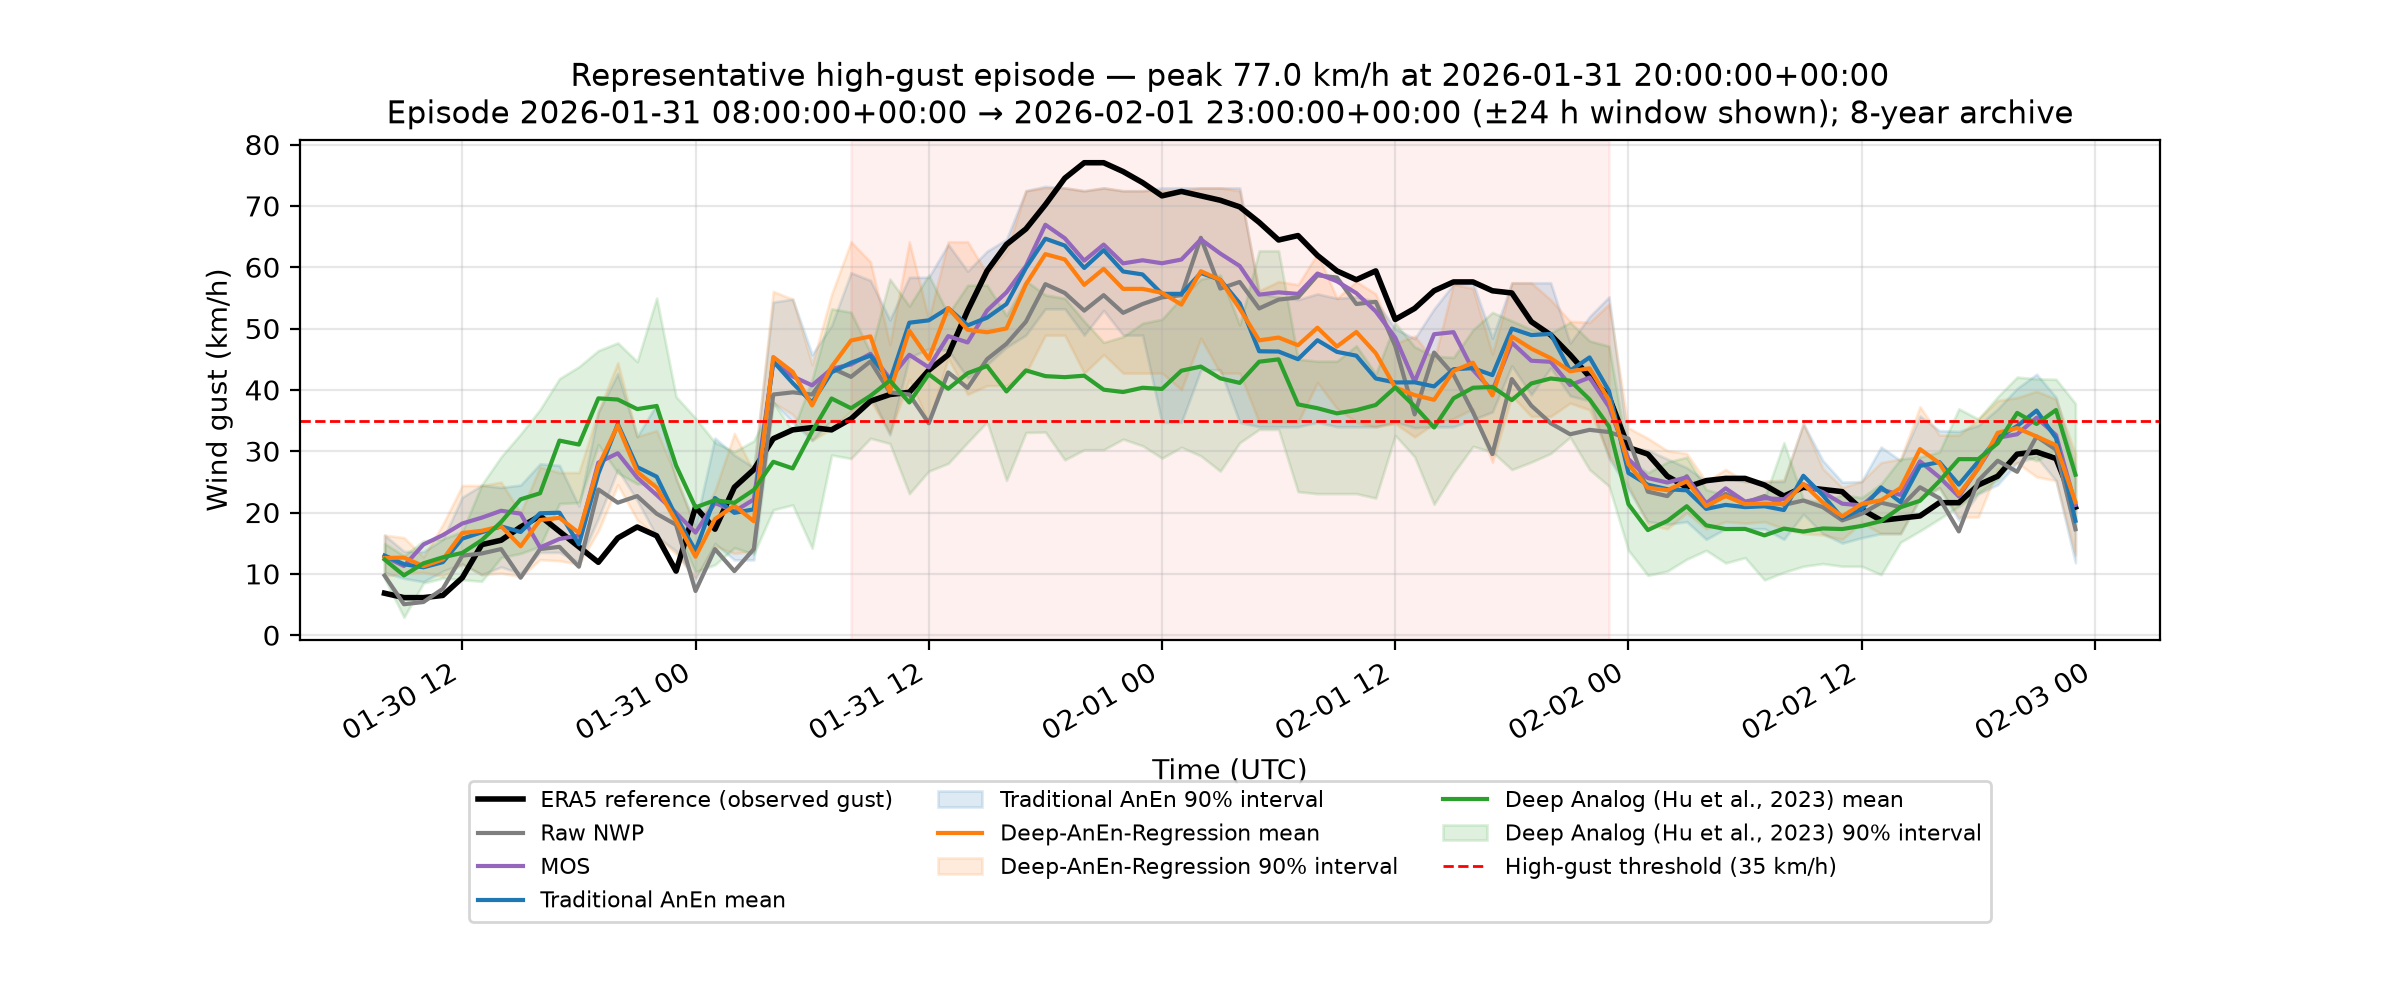

In [5]:
# --- Figures 1-4 ------------------------------------------------------------
for name, caption in [
    ("nested_fig1_framework", "Fig 1 — Experimental framework"),
    ("nested_fig2_verification_8yr", "Fig 2 — Overall verification (8-year archive)"),
    ("nested_fig3_archive_sensitivity", "Fig 3 — Archive-size sensitivity"),
    ("nested_fig4_episode", "Fig 4 — Representative high-gust episode"),
]:
    print(caption)
    display(Image(filename=f"plots/{name}.png"))

## §5 — Calibration, block-bootstrap CIs and Diebold–Mariano tests

Calibration is reported for the three ensemble methods: the rank (PIT)
histogram, the 90% prediction-interval coverage (nominal 0.90), and the
spread–skill ratio (1.0 = perfectly calibrated spread on average).
Uncertainty on the performance differences uses a **paired
block bootstrap**: whole independent episodes (81 in the test period)
are resampled with replacement (B = 2000, seed 42), preserving the
temporal dependence between high-gust events of the same storm; the
reported intervals are percentile 95% CIs on the score difference.
Diebold–Mariano tests use the same variant as before (loss
differential on per-event absolute errors, Newey–West HAC, Bartlett
kernel, lag h = ⌊T^(1/3)⌋, two-sided normal p).

In [6]:
# --- Calibration + uncertainty (8-year archive, primary) -------------------
reg = comp["regimes"]["nested_8yr"]
print("Calibration — 8-year archive")
cal = pd.DataFrame([
    {"method": m,
     "PI90 coverage": v["pi90_coverage"],
     "spread-skill ratio": v["spread_skill_ratio"],
     "rank histogram": v["rank_histogram_counts"]}
    for m, v in reg["calibration"].items()
])
display(cal)
print("\nPaired block-bootstrap 95% CIs, score differences vs Traditional AnEn (8-year)")
boot = pd.DataFrame([
    {"method": m,
     "dRMSE mean": v["rmse_diff_kmh"]["mean"],
     "dRMSE 95% CI": f"[{v['rmse_diff_kmh']['ci_lower']:+.2f}, {v['rmse_diff_kmh']['ci_upper']:+.2f}]",
     "dCRPS mean": v["crps_diff_kmh"]["mean"],
     "dCRPS 95% CI": f"[{v['crps_diff_kmh']['ci_lower']:+.2f}, {v['crps_diff_kmh']['ci_upper']:+.2f}]"}
    for m, v in reg["block_bootstrap"]["vs_Traditional AnEn"].items()
])
display(boot)
print("\nDiebold-Mariano tests vs Traditional AnEn (8-year; negative mean diff = method beats Traditional)")
dm = pd.DataFrame([
    {"method": m, "DM statistic": v["dm_statistic"], "p-value": v["p_value"],
     "mean |e| diff (km/h)": v["mean_abs_error_diff_kmh"]}
    for m, v in reg["diebold_mariano"]["vs_Traditional AnEn"].items()
])
display(dm)

Calibration — 8-year archive


,method,PI90 coverage,spread-skill ratio,rank histogram
0,Traditional AnEn,0.759,0.838,"[19, 31, 36, 45, 59, 52, 71, 62, 79, 72, 110, ..."
1,Deep-AnEn-Regression,0.753,0.841,"[22, 24, 27, 51, 52, 47, 60, 81, 77, 74, 107, ..."
2,"Deep Analog (Hu et al., 2023)",0.699,0.734,"[7, 12, 13, 25, 36, 38, 52, 52, 57, 67, 89, 12..."



Paired block-bootstrap 95% CIs, score differences vs Traditional AnEn (8-year)


,method,dRMSE mean,dRMSE 95% CI,dCRPS mean,dCRPS 95% CI
0,Raw NWP,5.240,"[+4.49, +6.04]",6.635,"[+5.86, +7.51]"
1,MOS,-0.158,"[-0.55, +0.17]",1.538,"[+1.31, +1.78]"
2,Deep-AnEn-Regression,0.110,"[+0.01, +0.20]",0.102,"[+0.03, +0.16]"
3,"Deep Analog (Hu et al., 2023)",2.020,"[+0.90, +3.16]",1.354,"[+0.74, +2.03]"



Diebold-Mariano tests vs Traditional AnEn (8-year; negative mean diff = method beats Traditional)


,method,DM statistic,p-value,mean |e| diff (km/h)
0,Raw NWP,15.469,0.000000e+00,5.062
1,MOS,-0.090,9.284589e-01,-0.012
2,Deep-AnEn-Regression,2.272,2.306792e-02,0.122
3,"Deep Analog (Hu et al., 2023)",5.000,5.740949e-07,1.697


## §6 — Training vs validation loss curves (supplementary)

Overfitting evidence for both neural models on every nested archive.
No curve shows validation diverging from training. Traditional AnEn
and MOS have no loss curve by design (non-parametric / closed-form
OLS) — this is stated explicitly rather than faked.

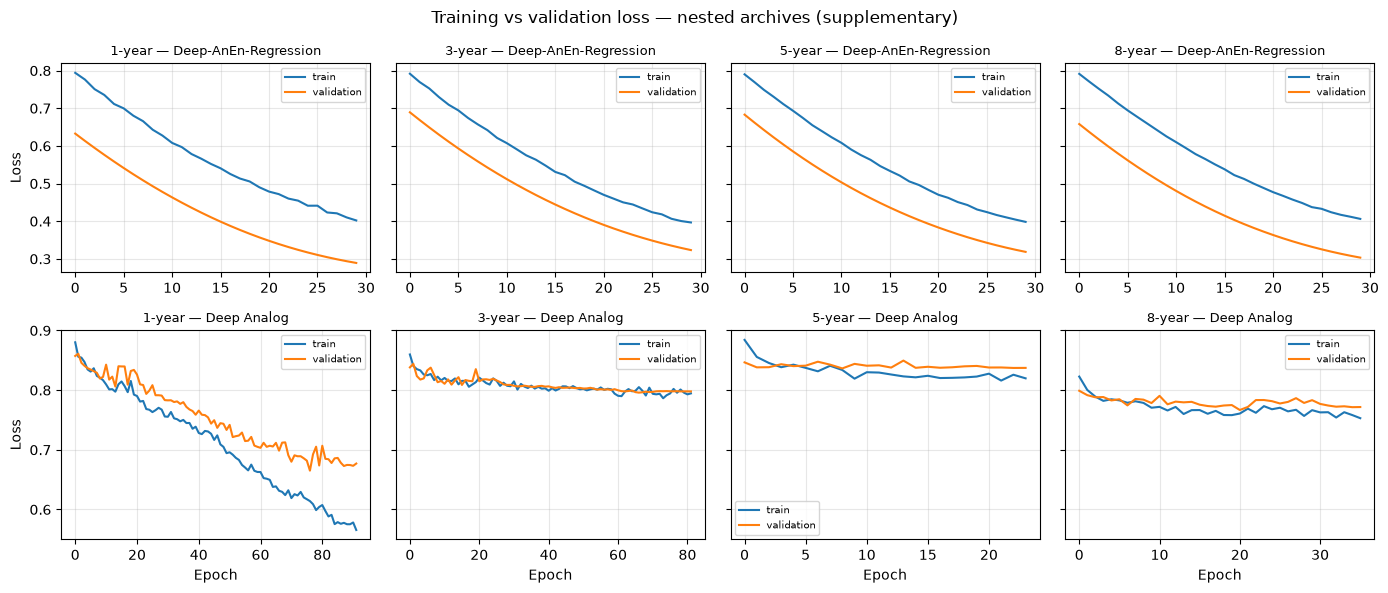

In [7]:
# --- Train/val loss curves (supplementary) ----------------------------------
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharey="row")
fig.suptitle("Training vs validation loss — nested archives (supplementary)", fontsize=12)
for j, regime in enumerate(NESTED_REGIMES):
    with open(f"metrics/deep_anen_regression_history_{regime}.json") as f:
        rh = json.load(f)["history"]
    with open(f"metrics/deep_anen_triplet_history_{regime}.json") as f:
        th = json.load(f)["history"]
    for i, (hist, title) in enumerate([(rh, "Deep-AnEn-Regression"), (th, "Deep Analog")]):
        ax = axes[i, j]
        ax.plot(hist["train"], label="train")
        ax.plot(hist["val"], label="validation")
        ax.set_title(f"{ARCH_LABELS[regime]} — {title}", fontsize=9)
        ax.grid(alpha=0.3)
        if j == 0:
            ax.set_ylabel("Loss")
        if i == 1:
            ax.set_xlabel("Epoch")
        ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("plots/nested_loss_curves.png", dpi=200)
plt.savefig("plots/nested_loss_curves.svg")
plt.show()

## §7 — Verification audit

The audit re-derives the protocol guarantees from the saved files:
identical test events across all four method runs per archive;
recomputed scores match the saved per-method metric files; split
sizes match the design; episode count matches. Analog selection itself
(training pool only, ±168 h exclusion) is enforced inside each
method's retrieval code and asserted at evaluation time in the method
runs (Traditional AnEn, Deep-AnEn-Regression and Deep Analog all
assert analogs lie in the training archive and outside the exclusion
window).

In [8]:
# --- Verification audit ------------------------------------------------------
for regime in NESTED_REGIMES:
    fcst, obs = load_regime(regime)
    assert len(obs) == 1286, regime
    # Recomputed scores match the saved metric files (tolerance 0.05 km/h).
    checks = []
    with open(f"metrics/traditional_anen_metrics_{regime}.json") as f:
        tm = json.load(f)
    checks.append(("Traditional RMSE", rmse(fcst["Traditional AnEn"][0], obs),
                   tm["rmse_traditional_anen_kmh"]))
    checks.append(("Traditional CRPS",
                   float(np.mean(properscoring.crps_ensemble(obs, fcst["Traditional AnEn"][1]))),
                   tm["crps_traditional_anen_kmh"]))
    with open(f"metrics/deep_anen_regression_metrics_{regime}.json") as f:
        rm = json.load(f)
    checks.append(("Regression RMSE", rmse(fcst["Deep-AnEn-Regression"][0], obs),
                   rm["rmse_deep_anen_regression_kmh"]))
    checks.append(("Regression CRPS",
                   float(np.mean(properscoring.crps_ensemble(obs, fcst["Deep-AnEn-Regression"][1]))),
                   rm["crps_deep_anen_regression_kmh"]))
    with open(f"metrics/deep_anen_triplet_metrics_{regime}.json") as f:
        hm = json.load(f)
    checks.append(("Deep Analog RMSE", rmse(fcst["Deep Analog (Hu et al., 2023)"][0], obs),
                   hm["rmse_kmh"]))
    checks.append(("Deep Analog CRPS",
                   float(np.mean(properscoring.crps_ensemble(obs, fcst["Deep Analog (Hu et al., 2023)"][1]))),
                   hm["crps_kmh"]))
    with open(f"metrics/mos_metrics_{regime}.json") as f:
        mm = json.load(f)
    checks.append(("MOS RMSE", rmse(fcst["MOS"][0], obs), mm["rmse_mos_kmh"]))
    checks.append(("MOS CRPS (= MAE)", mae(fcst["MOS"][0], obs), mm["crps_mos_kmh"]))
    for name, got, want in checks:
        assert abs(got - want) < 0.05, f"{regime} {name}: recomputed {got:.2f} != saved {want}"
    print(f"{ARCH_LABELS[regime]}: all {len(checks)} recomputed scores match the saved "
          f"metrics; 1,286 events identical across methods.")
print("\nAudit passed: identical test events, split sizes, episode count, "
      "and all recomputed scores match the saved metric files.")

1-year: all 8 recomputed scores match the saved metrics; 1,286 events identical across methods.
3-year: all 8 recomputed scores match the saved metrics; 1,286 events identical across methods.
5-year: all 8 recomputed scores match the saved metrics; 1,286 events identical across methods.
8-year: all 8 recomputed scores match the saved metrics; 1,286 events identical across methods.

Audit passed: identical test events, split sizes, episode count, and all recomputed scores match the saved metric files.


## §8 — Limitations

**Verification is against reanalysis, not station observations.**
The reference observations are ERA5 reanalysis values served by the
Open-Meteo Archive API. ERA5 is a model-assimilated product: it blends
observations with a numerical weather prediction model, so it is
smoother than point station measurements and can under-represent the
sharpest local gust peaks. All verification scores in this notebook —
including the 35 km/h high-gust event definition — are therefore scores
against reanalysis, and the ranking of methods could shift if verified
against independent station observations. The same reanalysis reference
is used for every method and every archive, so the *comparison* is
internally consistent; the absolute scores are not station-verified.

**NWP reproducibility.** The forecast series comes from the
Open-Meteo Previous-Runs API with no `models` parameter (provider
default, auto / best-match); empirically it matches NOAA GFS
(seamless) at sampled windows. The endpoint exposes no per-hour model
attribution or run-initialisation field, so the exact model run behind
each hourly forecast cannot be recovered from the response.

**Single location, single variable.** All results are for one grid
point (Atlanta, GA) and one target variable (10 m wind gust). The
archive-size finding is a controlled experiment at that location, not
a multi-site generalization.